# From Combine speed to NFL routes
### What does sensor speed tell us that the 40-yard dash does not?

The 2027 Big Data Bowl asks how Combine movement translates to NFL performance. This notebook follows one position group, one drill, and one route: wide receivers in the Combine `GO_ROUTE_RIGHT` drill and their rookie-season NFL `GO` routes. It uses 10 Hz Combine and regular-season game tracking.

**Finding:** Combine go-drill speed may help estimate a rookie's on-field go-route speed beyond official 40-yard time and draft position. It adds almost nothing to predicting separation at pass release. The speed improvement is promising but uncertain in this small sample, so the result is a development lead rather than a player-ranking rule.

## Football question

A straight-line 40 tells teams how quickly a player can run under standardized conditions. The position drill shows speed while running a football route. If that added context matters, it should improve prediction of **NFL route speed** before we ask it to predict **separation**, which also depends on coverage, timing, and play design. This two-step check distinguishes a physical transfer from an on-field outcome.

## Study design

- **Players:** 106 Combine wide receivers; 54 had a Combine go drill plus at least 10 rookie NFL go routes with valid tracking and 10 of those routes with separation. The held-out classes contain 22 players from 2023, 18 from 2024, and 14 from 2025.
- **Sensor feature:** median across Combine attempts of the 90th percentile tracking speed.
- **NFL outcomes:** mean 90th percentile tracking speed between ball snap and pass release on rookie go routes, and mean separation at pass release on those routes.
- **Benchmark:** official 40-yard time and overall draft pick. Missing 40 times are filled with the training-class median; missing draft picks are assigned 260.
- **Validation:** fit on two draft classes and predict the third. Repeat for each class. All scaling and 40-time imputation occur inside the training fold.

Each player contributes one outcome to the validation. The sample is small and route labels do not guarantee identical tactics or geometry.

## Results to inspect

In the 2025 class, adding Combine speed changed held-out go-route speed RMSE from **0.433 to 0.354 yd/s** for 14 players. Across all three held-out classes, RMSE changed from **0.408 to 0.358 yd/s**. A paired bootstrap interval for the pooled RMSE change was **-0.113 to +0.015 yd/s**, so the improvement is uncertain.

For separation, the pooled RMSE was **0.436 yd** with the benchmark and **0.434 yd** after adding sensor speed. The paired interval for the change was **-0.018 to +0.014 yd**. The sensor measure therefore appears more relevant to route speed than to whether a receiver is open.

A descriptive coverage check found similar raw speed correlations within man coverage (ρ = 0.45, 47 players) and zone coverage (ρ = 0.40, 54 players). Those checks are exploratory and do not substitute for a coverage-adjusted causal model.

## What a team can do with this

Treat go-drill speed as a possible **movement baseline** for a rookie. After a player has NFL tracking data, compare observed route speed with that baseline to investigate whether the player is using their physical capacity in games. Do not turn the sensor feature into a separation grade: this analysis found no meaningful held-class gain for that outcome. Route assignment, coverage, target selection, and quarterback timing remain essential context.

The weekly table is retrospective and its players were selected using full-season route counts. The feature emerged from a broader exploratory project, so even the draft-class checks are not an untouched external validation set. The bootstrap resamples held-class predictions while keeping fitted models fixed and therefore does not capture all training-sample uncertainty. The results are observational and require confirmation in later cohorts.

## Code appendix: reproduce the analysis

Attach the NFL Big Data Bowl 2027 competition dataset in Kaggle. The notebook searches `/kaggle/input` for the CSVs. Locally, it uses `data/raw/` and streams game tracking from the original ZIP when needed. Generated tables go to `outputs/`; the summary image goes to `figures/`.

In [1]:
"""Focused rookie go-route transfer analysis for the Jupyter submission.

This file mirrors the executable cells in notebooks/go_route_transfer.ipynb.
The competition CSVs remain external to the repository.
"""

from __future__ import annotations

import json
import os
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

if "__file__" in globals():
    ROOT = Path(__file__).resolve().parents[1]
else:
    ROOT = Path.cwd()
    if not (ROOT / "data/raw").is_dir() and (ROOT.parent / "data/raw").is_dir():
        ROOT = ROOT.parent


def find_data_dir() -> Path:
    configured = os.environ.get("BDB_DATA_DIR")
    candidates = [Path(configured)] if configured else []
    candidates.extend([ROOT / "data/raw", Path("/kaggle/input/nfl-big-data-bowl-2027")])
    for candidate in candidates:
        for folder in (candidate, candidate / "nfl-big-data-bowl-2027"):
            if (folder / "players.csv").is_file() and (folder / "combine_tracking.csv").is_file():
                return folder
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        for player_file in kaggle_root.rglob("players.csv"):
            if (player_file.parent / "combine_tracking.csv").is_file():
                return player_file.parent
    raise FileNotFoundError("Attach the NFL Big Data Bowl 2027 data or set BDB_DATA_DIR")


DATA = find_data_dir()
ARCHIVE = Path(os.environ.get("BDB_ARCHIVE", Path.home() / "Downloads/nfl-big-data-bowl-2027.zip"))
OUT = Path(os.environ.get("BDB_OUTPUT_DIR", ROOT / "outputs"))
FIGURES = Path(os.environ.get("BDB_FIGURE_DIR", ROOT / "figures"))

In [2]:
def combine_go_speed(wr_ids: set[int]) -> pd.DataFrame:
    """Median of attempt-level 90th percentile sensor speeds, in yards/second."""
    cols = ["draft_year", "event_id", "nfl_id", "entity_type", "drill_name", "attempt", "s"]
    tracking = pd.read_csv(DATA / "combine_tracking.csv", usecols=cols)
    tracking = tracking[
        tracking.nfl_id.isin(wr_ids)
        & tracking.entity_type.eq("PLAYER")
        & tracking.drill_name.eq("GO_ROUTE_RIGHT")
    ]
    attempts = tracking.groupby(
        ["draft_year", "nfl_id", "attempt", "event_id"], observed=True
    ).s.quantile(0.9).reset_index(name="combine_go_speed_p90")
    return attempts.groupby("nfl_id", as_index=False).combine_go_speed_p90.median()

def rookie_go_plays(wr: pd.DataFrame) -> pd.DataFrame:
    games = pd.read_csv(DATA / "games.csv", usecols=["game_id", "season", "season_type", "week"])
    cols = ["game_id", "play_id", "nfl_id", "route_ran", "separation_at_pass_forward",
            "team_coverage_man_zone"]
    play = pd.read_csv(DATA / "player_play.csv", usecols=cols)
    play = play.merge(games, on="game_id", validate="many_to_one")
    play = play.merge(wr[["nfl_id", "draft_year"]], on="nfl_id", validate="many_to_one")
    return play[
        play.route_ran.eq("GO")
        & play.season_type.eq("REG")
        & play.season.eq(play.draft_year)
    ].copy()

def game_go_speed(target_plays: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Read targeted players and global event markers, then measure snap-to-pass speed."""
    keys = target_plays[["game_id", "play_id", "nfl_id"]].drop_duplicates()
    player_keys = set(map(tuple, keys.itertuples(index=False, name=None)))
    play_keys = set(map(tuple, keys[["game_id", "play_id"]].drop_duplicates().itertuples(index=False, name=None)))
    wr_ids = set(keys.nfl_id.astype(int))
    markers: dict[tuple[int, int], dict[str, pd.Timestamp]] = {}
    chunks = []
    rows_by_season = {}
    cols = ["game_id", "play_id", "nfl_id", "time", "s", "event"]
    archive = ZipFile(ARCHIVE) if ARCHIVE.exists() else None
    try:
        for season in sorted(target_plays.season.astype(int).unique()):
            path = DATA / f"game_tracking_{season}.csv"
            if path.is_file():
                stream = path.open("rb")
            elif archive is not None:
                member = f"nfl-big-data-bowl-2027/game_tracking_{season}.csv"
                if member not in archive.namelist():
                    raise FileNotFoundError(member)
                stream = archive.open(member)
            else:
                raise FileNotFoundError(f"Missing {path}; set BDB_ARCHIVE for a local ZIP")
            season_count = 0
            with stream:
                for chunk in pd.read_csv(stream, usecols=cols, chunksize=750_000):
                    events = chunk[chunk.event.isin(["ball_snap", "pass_forward"])]
                    if not events.empty:
                        events = events.loc[
                            [key in play_keys for key in zip(events.game_id, events.play_id)]
                        ].copy()
                    if not events.empty:
                        events["timestamp"] = pd.to_datetime(events.time, errors="coerce", utc=True)
                        for (gid, pid, event), group in events.groupby(
                            ["game_id", "play_id", "event"], sort=False
                        ):
                            timestamp = group.timestamp.min()
                            current = markers.setdefault((int(gid), int(pid)), {}).get(event)
                            if pd.notna(timestamp) and (current is None or timestamp < current):
                                markers[(int(gid), int(pid))][event] = timestamp
                    candidate = chunk[chunk.nfl_id.isin(wr_ids)]
                    if candidate.empty:
                        continue
                    keep = [key in player_keys for key in zip(
                        candidate.game_id, candidate.play_id, candidate.nfl_id
                    )]
                    if any(keep):
                        chosen = candidate.loc[keep].copy()
                        chunks.append(chosen)
                        season_count += len(chosen)
            rows_by_season[str(season)] = season_count
    finally:
        if archive is not None:
            archive.close()
    if not chunks:
        raise ValueError("No game tracking rows matched the rookie go routes")
    tracks = pd.concat(chunks, ignore_index=True)
    tracks["timestamp"] = pd.to_datetime(tracks.time, errors="coerce", utc=True)
    rows = []
    for (gid, pid, nfl_id), group in tracks.groupby(["game_id", "play_id", "nfl_id"], sort=False):
        event_times = markers.get((int(gid), int(pid)), {})
        snap, release = event_times.get("ball_snap"), event_times.get("pass_forward")
        if snap is None or release is None or release <= snap:
            continue
        window = group[(group.timestamp >= snap) & (group.timestamp <= release)]
        if len(window) < 3 or window.s.notna().sum() < 3:
            continue
        rows.append((gid, pid, nfl_id, float(window.s.quantile(0.9)), len(window)))
    audit = {
        "candidate_player_plays": int(len(keys)),
        "tracking_rows_retained": int(len(tracks)),
        "valid_snap_to_pass_windows": int(len(rows)),
        "tracking_rows_by_season": rows_by_season,
    }
    return pd.DataFrame(rows, columns=["game_id", "play_id", "nfl_id", "game_go_speed_p90", "frames"]), audit

def player_table(wr: pd.DataFrame, play: pd.DataFrame, tracks: pd.DataFrame,
                 combine_speed: pd.DataFrame) -> pd.DataFrame:
    # Evaluate both outcomes on routes with a valid tracking window so that
    # speed and separation refer to the same plays for each receiver.
    joined = play.merge(tracks, on=["game_id", "play_id", "nfl_id"], how="inner", validate="one_to_one")
    player = joined.groupby("nfl_id").agg(
        tracked_go_routes=("game_go_speed_p90", "count"),
        mean_nfl_go_speed=("game_go_speed_p90", "mean"),
        measured_separation_routes=("separation_at_pass_forward", "count"),
        mean_separation=("separation_at_pass_forward", "mean"),
    ).reset_index()
    player = player.merge(combine_speed, on="nfl_id")
    player = player.merge(
        wr[["nfl_id", "draft_year", "forty", "draft_overall_pick"]],
        on="nfl_id", validate="one_to_one"
    )
    return player[
        player.tracked_go_routes.ge(10) & player.measured_separation_routes.ge(10)
    ].copy()

def coverage_check(play: pd.DataFrame, tracks: pd.DataFrame, player: pd.DataFrame,
                   combine_speed: pd.DataFrame) -> pd.DataFrame:
    """Descriptive transfer check within man and zone coverage, using primary players."""
    joined = play.merge(tracks, on=["game_id", "play_id", "nfl_id"], how="inner")
    joined = joined[joined.nfl_id.isin(player.nfl_id)]
    rows = []
    for coverage in ("MAN_COVERAGE", "ZONE_COVERAGE"):
        group = joined[joined.team_coverage_man_zone.eq(coverage)]
        means = group.groupby("nfl_id").agg(
            mean_nfl_go_speed=("game_go_speed_p90", "mean"),
            tracked_go_routes=("game_go_speed_p90", "count"),
        ).reset_index()
        means = means[means.tracked_go_routes.ge(5)].merge(combine_speed, on="nfl_id")
        rho, p = spearmanr(means.combine_go_speed_p90, means.mean_nfl_go_speed)
        rows.append({
            "coverage": coverage, "n_players": int(len(means)),
            "minimum_routes_per_player": 5,
            "spearman_rho": float(rho), "exploratory_p": float(p),
        })
    return pd.DataFrame(rows)

def weekly_translation(play: pd.DataFrame, tracks: pd.DataFrame,
                       predictions: pd.DataFrame) -> pd.DataFrame:
    """A 2025 pilot table comparing cumulative route speed with a prior-class estimate."""
    expected = predictions[predictions.draft_year.eq(2025)][
        ["nfl_id", "mean_nfl_go_speed_plus_sensor_prediction"]
    ]
    tracked = play.merge(tracks, on=["game_id", "play_id", "nfl_id"], how="inner")
    tracked = tracked.merge(expected, on="nfl_id", how="inner")
    weekly = tracked.groupby(["nfl_id", "week"], as_index=False).agg(
        routes=("game_go_speed_p90", "size"),
        sum_route_speed=("game_go_speed_p90", "sum"),
        expected_rookie_speed=("mean_nfl_go_speed_plus_sensor_prediction", "first"),
    ).sort_values(["nfl_id", "week"])
    weekly["cumulative_routes"] = weekly.groupby("nfl_id").routes.cumsum()
    weekly["cumulative_speed"] = weekly.groupby("nfl_id").sum_route_speed.cumsum() / weekly.cumulative_routes
    weekly["speed_gap"] = weekly.cumulative_speed - weekly.expected_rookie_speed
    return weekly[weekly.cumulative_routes.ge(10)][
        ["nfl_id", "week", "routes", "cumulative_routes", "cumulative_speed",
         "expected_rookie_speed", "speed_gap"]
    ].copy()

In [3]:
def design_matrices(train: pd.DataFrame, test: pd.DataFrame,
                    include_sensor: bool) -> tuple[np.ndarray, np.ndarray]:
    """Impute and scale using the training draft classes only."""
    train_controls = train[["forty", "draft_overall_pick"]].copy()
    test_controls = test[["forty", "draft_overall_pick"]].copy()
    forty_median = train_controls.forty.median()
    for frame in (train_controls, test_controls):
        frame["forty"] = frame.forty.fillna(forty_median)
        frame["draft_overall_pick"] = frame.draft_overall_pick.fillna(260)
    mean = train_controls.mean()
    scale = train_controls.std(ddof=0).replace(0, 1)
    x_train = ((train_controls - mean) / scale).to_numpy(dtype=float)
    x_test = ((test_controls - mean) / scale).to_numpy(dtype=float)
    if include_sensor:
        sensor_mean = train.combine_go_speed_p90.mean()
        sensor_scale = train.combine_go_speed_p90.std(ddof=0)
        sensor_scale = sensor_scale if sensor_scale else 1
        x_train = np.column_stack([x_train, (train.combine_go_speed_p90 - sensor_mean) / sensor_scale])
        x_test = np.column_stack([x_test, (test.combine_go_speed_p90 - sensor_mean) / sensor_scale])
    return np.column_stack([np.ones(len(x_train)), x_train]), np.column_stack([np.ones(len(x_test)), x_test])

def class_held_out_predictions(player: pd.DataFrame) -> pd.DataFrame:
    """Each draft class is predicted by models fit to the other two classes."""
    pieces = []
    for held_class in sorted(player.draft_year.unique()):
        train = player[player.draft_year.ne(held_class)]
        test = player[player.draft_year.eq(held_class)].copy()
        if len(train) < 20 or len(test) < 5:
            raise ValueError(f"Too few players for draft-class holdout {held_class}")
        for outcome in ("mean_nfl_go_speed", "mean_separation"):
            for label, include_sensor in (("baseline", False), ("plus_sensor", True)):
                x_train, x_test = design_matrices(train, test, include_sensor)
                beta = np.linalg.lstsq(x_train, train[outcome].to_numpy(dtype=float), rcond=None)[0]
                test[f"{outcome}_{label}_prediction"] = x_test @ beta
        pieces.append(test)
    return pd.concat(pieces, ignore_index=True).sort_values(["draft_year", "nfl_id"])

def cv_summary(predictions: pd.DataFrame, bootstrap_reps: int = 3000) -> pd.DataFrame:
    rng = np.random.default_rng(2027)
    rows = []
    years = sorted(predictions.draft_year.unique())
    for outcome in ("mean_nfl_go_speed", "mean_separation"):
        actual = predictions[outcome].to_numpy(dtype=float)
        baseline = predictions[f"{outcome}_baseline_prediction"].to_numpy(dtype=float)
        plus = predictions[f"{outcome}_plus_sensor_prediction"].to_numpy(dtype=float)
        for held_class in [*years, "pooled"]:
            mask = np.ones(len(predictions), dtype=bool) if held_class == "pooled" else predictions.draft_year.eq(held_class).to_numpy()
            base_rmse = float(np.sqrt(np.mean((actual[mask] - baseline[mask]) ** 2)))
            plus_rmse = float(np.sqrt(np.mean((actual[mask] - plus[mask]) ** 2)))
            row = {
                "outcome": outcome, "held_draft_class": held_class,
                "n_players": int(mask.sum()), "baseline_rmse": base_rmse,
                "plus_sensor_rmse": plus_rmse, "rmse_change_plus_minus_baseline": plus_rmse - base_rmse,
            }
            if held_class == "pooled":
                class_indices = [np.flatnonzero(predictions.draft_year.eq(year).to_numpy()) for year in years]
                changes = []
                for _ in range(bootstrap_reps):
                    sample = np.concatenate([rng.choice(ids, size=len(ids), replace=True) for ids in class_indices])
                    changes.append(np.sqrt(np.mean((actual[sample] - plus[sample]) ** 2))
                                   - np.sqrt(np.mean((actual[sample] - baseline[sample]) ** 2)))
                row["paired_bootstrap_ci95_low"] = float(np.quantile(changes, 0.025))
                row["paired_bootstrap_ci95_high"] = float(np.quantile(changes, 0.975))
            rows.append(row)
    return pd.DataFrame(rows)

In [4]:
def make_figure(predictions: pd.DataFrame, summary: pd.DataFrame) -> None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), layout="constrained")
    colors = {2023: "#176B87", 2024: "#BA6731", 2025: "#4A7856"}
    for year, group in predictions.groupby("draft_year"):
        axes[0].scatter(group.combine_go_speed_p90, group.mean_nfl_go_speed,
                        label=str(year), color=colors.get(year, "#555555"), alpha=0.82, s=32)
    rho, _ = spearmanr(predictions.combine_go_speed_p90, predictions.mean_nfl_go_speed)
    axes[0].set(title=f"Raw movement transfer (n={len(predictions)}, ρ={rho:.2f})",
                xlabel="Combine go-drill speed (yd/s)", ylabel="Mean rookie NFL go-route speed (yd/s)")
    axes[0].legend(title="Draft class", frameon=False)
    for ax, outcome, title, unit in [
        (axes[1], "mean_nfl_go_speed", "Predicting rookie go-route speed", "RMSE (yd/s)"),
        (axes[2], "mean_separation", "Predicting separation at pass release", "RMSE (yd)"),
    ]:
        table = summary[(summary.outcome.eq(outcome)) & summary.held_draft_class.ne("pooled")]
        years = table.held_draft_class.astype(str).tolist()
        xx = np.arange(len(years))
        ax.bar(xx - 0.17, table.baseline_rmse, width=0.34, color="#667784", label="40 + draft pick")
        ax.bar(xx + 0.17, table.plus_sensor_rmse, width=0.34, color="#176B87", label="+ Combine speed")
        ax.set(title=title, xlabel="Held-out draft class", ylabel=unit,
               xticks=xx, xticklabels=years)
        ax.legend(frameon=False, fontsize=8)
        ax.set_ylim(bottom=0)
    for ax in axes:
        ax.grid(axis="y", alpha=0.18)
    fig.suptitle("What Combine go-drill speed adds to rookie route outcomes", fontsize=14)
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / "go_route_transfer.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

In [5]:
def main() -> None:
    OUT.mkdir(parents=True, exist_ok=True)
    players = pd.read_csv(DATA / "players.csv")
    combine_results = pd.read_csv(DATA / "combine_results.csv")
    wr = players.merge(combine_results, on=["nfl_id", "draft_year"])
    wr = wr[wr.nfl_position.eq("WR") & wr.combine_position.eq("WR")].copy()
    combine_speed = combine_go_speed(set(wr.nfl_id.astype(int)))
    play = rookie_go_plays(wr)
    tracks, audit = game_go_speed(play)
    player = player_table(wr, play, tracks, combine_speed)
    coverage = coverage_check(play, tracks, player, combine_speed)
    predictions = class_held_out_predictions(player)
    summary = cv_summary(predictions)
    weekly = weekly_translation(play, tracks, predictions)
    player.to_csv(OUT / "rookie_go_player_table.csv", index=False)
    predictions.to_csv(OUT / "rookie_go_cv_predictions.csv", index=False)
    summary.to_csv(OUT / "rookie_go_cv_summary.csv", index=False)
    coverage.to_csv(OUT / "rookie_go_coverage_check.csv", index=False)
    weekly.to_csv(OUT / "rookie_go_weekly_translation.csv", index=False)
    make_figure(predictions, summary)
    audit.update({
        "combine_wr_players": int(wr.nfl_id.nunique()),
        "rookie_go_players_with_10_routes": int(len(player)),
        "rookie_go_players_by_draft_class": {str(k): int(v) for k, v in player.draft_year.value_counts().sort_index().items()},
        "missing_forty_players": int(player.forty.isna().sum()),
        "missing_draft_pick_players": int(player.draft_overall_pick.isna().sum()),
        "weekly_pilot_rows": int(len(weekly)),
        "route_speed_unit": "yards per second",
        "separation_unit": "yards",
        "validation": "Leave-one-draft-class-out, with train-only imputation and scaling",
        "bootstrap": "Paired, stratified resampling of held-class predictions; conditions on fitted models",
    })
    (OUT / "rookie_go_audit.json").write_text(json.dumps(audit, indent=2))
    print(json.dumps(audit, indent=2))
    print(summary.round(4).to_string(index=False))
    print("\nCoverage check (descriptive):\n", coverage.round(3).to_string(index=False))

main()

{
  "candidate_player_plays": 3340,
  "tracking_rows_retained": 255380,
  "valid_snap_to_pass_windows": 2971,
  "tracking_rows_by_season": {
    "2023": 110963,
    "2024": 81114,
    "2025": 63303
  },
  "combine_wr_players": 106,
  "rookie_go_players_with_10_routes": 54,
  "rookie_go_players_by_draft_class": {
    "2023": 22,
    "2024": 18,
    "2025": 14
  },
  "missing_forty_players": 4,
  "missing_draft_pick_players": 5,
  "weekly_pilot_rows": 134,
  "route_speed_unit": "yards per second",
  "separation_unit": "yards",
  "validation": "Leave-one-draft-class-out, with train-only imputation and scaling",
  "bootstrap": "Paired, stratified resampling of held-class predictions; conditions on fitted models"
}
          outcome held_draft_class  n_players  baseline_rmse  plus_sensor_rmse  rmse_change_plus_minus_baseline  paired_bootstrap_ci95_low  paired_bootstrap_ci95_high
mean_nfl_go_speed             2023         22         0.4328            0.3605                          -0.0723  

## Figure and compact output

Bars show RMSE on players whose draft class was omitted from model fitting. Lower bars are better. The scatter is descriptive; it does not show adjusted or held-out effects.

,outcome,held_draft_class,n_players,baseline_rmse,plus_sensor_rmse,rmse_change_plus_minus_baseline,paired_bootstrap_ci95_low,paired_bootstrap_ci95_high
0,mean_nfl_go_speed,2023,22,0.433,0.360,-0.072,NaN,NaN
1,mean_nfl_go_speed,2024,18,0.353,0.358,0.006,NaN,NaN
2,mean_nfl_go_speed,2025,14,0.433,0.354,-0.079,NaN,NaN
3,mean_nfl_go_speed,pooled,54,0.408,0.358,-0.050,-0.113,0.015
4,mean_separation,2023,22,0.475,0.469,-0.006,NaN,NaN
5,mean_separation,2024,18,0.480,0.484,0.004,NaN,NaN
6,mean_separation,2025,14,0.290,0.285,-0.005,NaN,NaN
7,mean_separation,pooled,54,0.436,0.434,-0.002,-0.018,0.014


,coverage,n_players,minimum_routes_per_player,spearman_rho,exploratory_p
0,MAN_COVERAGE,47,5,0.450,0.002
1,ZONE_COVERAGE,54,5,0.397,0.003


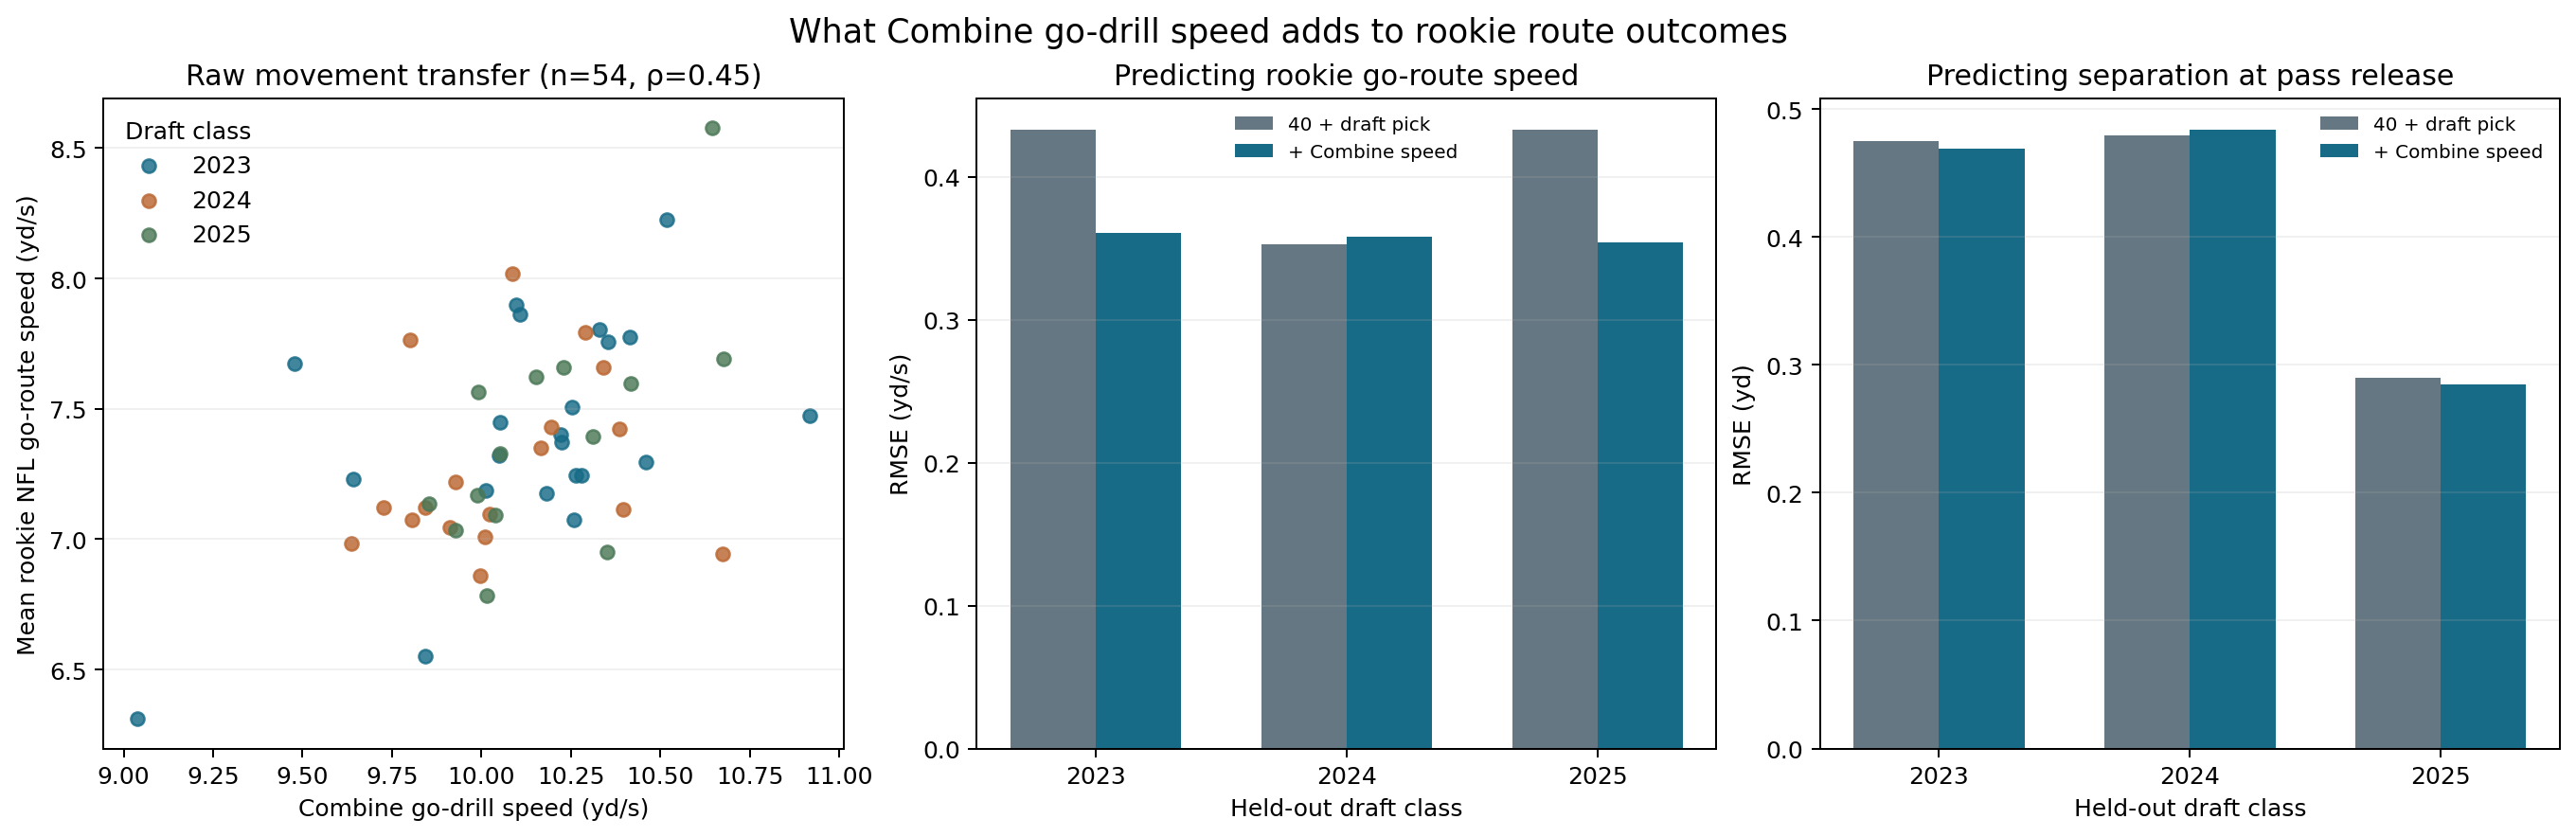

In [6]:
from IPython.display import Image, display

summary = pd.read_csv(OUT / "rookie_go_cv_summary.csv")
coverage = pd.read_csv(OUT / "rookie_go_coverage_check.csv")
display(summary.round(3))
display(coverage.round(3))
display(Image(filename=str(FIGURES / "go_route_transfer.png")))